In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from scipy.stats import norm

In [ ]:
np.random.seed(42)

n = 10000

data = pd.DataFrame({
    "Age": np.random.randint(21, 60, n),
    "Income": np.random.randint(20000, 200000, n),
    "CreditScore": np.random.randint(300, 850, n),
    "LoanAmount": np.random.randint(10000, 1000000, n),
    "LoanTerm": np.random.choice([12, 24, 36, 48, 60], n),
    "EmploymentYears": np.random.randint(0, 20, n),
    "ExistingLoans": np.random.randint(0, 5, n),
    "DebtToIncome": np.round(np.random.uniform(0.05, 0.80, n), 2),
    "EmploymentType": np.random.choice(
        ["Salaried", "Self-Employed", "Business"], n
    ),
    "Education": np.random.choice(
        ["Graduate", "Postgraduate", "Undergraduate"], n
    )
})

# Generate approval probability
score = (
    0.006 * (data["CreditScore"] - 500)
    + 0.000005 * (data["Income"] - 50000)
    - 0.000002 * data["LoanAmount"]
    - 2.5 * (data["DebtToIncome"] - 0.30)
    + 0.08 * data["EmploymentYears"]
    - 0.20 * data["ExistingLoans"]
)

probability = 1 / (1 + np.exp(-score))

data["LoanApproved"] = np.random.binomial(1, probability)

data.head()

,Age,Income,CreditScore,LoanAmount,LoanTerm,EmploymentYears,ExistingLoans,DebtToIncome,EmploymentType,Education,LoanApproved
0,59,171306,737,401692,60,8,0,0.29,Salaried,Undergraduate,1
1,49,41381,525,458467,60,1,0,0.57,Business,Graduate,0
2,35,168346,607,968149,12,19,1,0.51,Salaried,Undergraduate,0
3,28,103108,647,143617,24,5,1,0.38,Business,Postgraduate,0
4,41,69892,775,269249,24,17,3,0.61,Salaried,Graduate,0


In [ ]:
print("Shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nApproval distribution:")
print(data["LoanApproved"].value_counts())

print("\nApproval percentage:")
print(data["LoanApproved"].mean() * 100)

Shape: (10000, 11)

Missing values:
Age                0
Income             0
CreditScore        0
LoanAmount         0
LoanTerm           0
EmploymentYears    0
ExistingLoans      0
DebtToIncome       0
EmploymentType     0
Education          0
LoanApproved       0
dtype: int64

Approval distribution:
LoanApproved
0    5450
1    4550
Name: count, dtype: int64

Approval percentage:
45.5


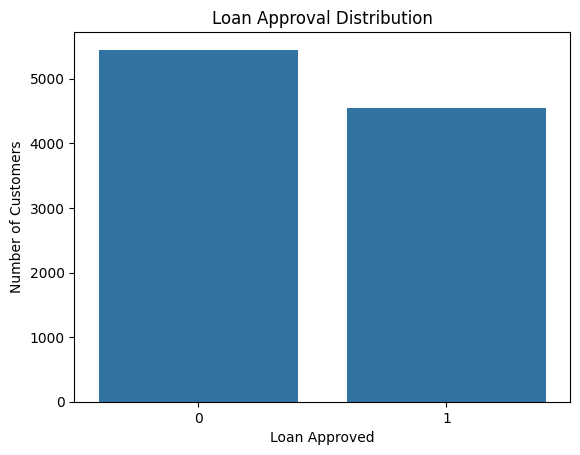

In [ ]:
sns.countplot(data=data, x="LoanApproved")

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Approved")
plt.ylabel("Number of Customers")
plt.show()

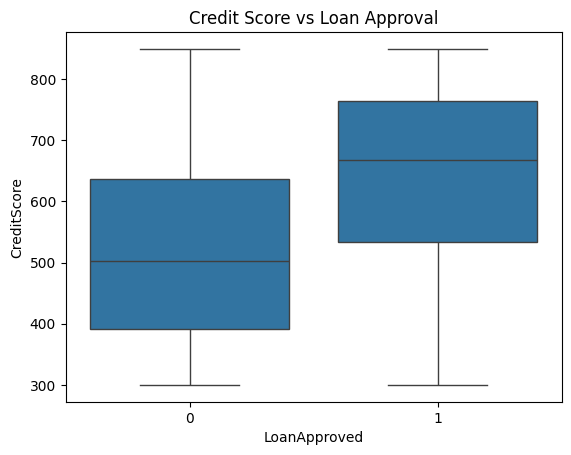

In [ ]:
sns.boxplot(data=data, x="LoanApproved", y="CreditScore")

plt.title("Credit Score vs Loan Approval")
plt.show()

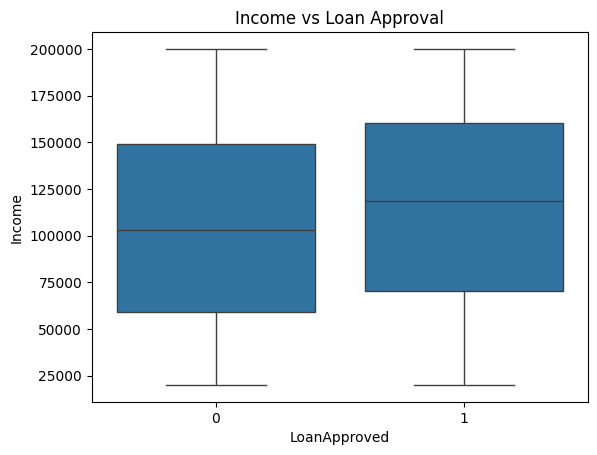

In [ ]:
sns.boxplot(data=data, x="LoanApproved", y="Income")

plt.title("Income vs Loan Approval")
plt.show()

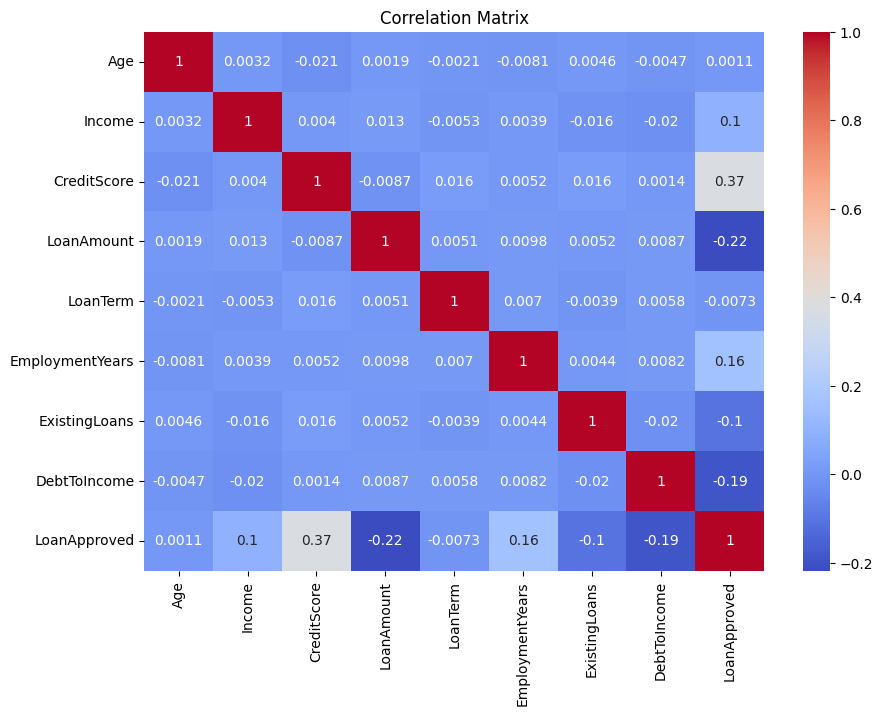

In [ ]:
plt.figure(figsize=(10, 7))

numeric_data = data.select_dtypes(include=np.number)

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
X = data.drop("LoanApproved", axis=1)

y = data["LoanApproved"]

In [ ]:
numeric_features = [
    "Age",
    "Income",
    "CreditScore",
    "LoanAmount",
    "LoanTerm",
    "EmploymentYears",
    "ExistingLoans",
    "DebtToIncome"
]

categorical_features = [
    "EmploymentType",
    "Education"
]

In [ ]:
numeric_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor=ColumnTransformer([
    ("numeric",numeric_pipeline,numeric_features),
    ("categorical",categorical_pipeline,categorical_features)
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 10)
Testing data: (2000, 10)


In [ ]:
model=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Income',
                                                   'CreditScore', 'LoanAmount',
                                                   'LoanTerm',
                                                   'EmploymentYears',
                                                   'ExistingLoans',
                                                   'DebtToIncome']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['EmploymentType',
                                                   'Education'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_probability)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

Accuracy : 0.7235
Precision: 0.6968
Recall   : 0.6945
F1 Score : 0.6957
ROC-AUC  : 0.8056


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.75      0.75      1090
           1       0.70      0.69      0.70       910

    accuracy                           0.72      2000
   macro avg       0.72      0.72      0.72      2000
weighted avg       0.72      0.72      0.72      2000



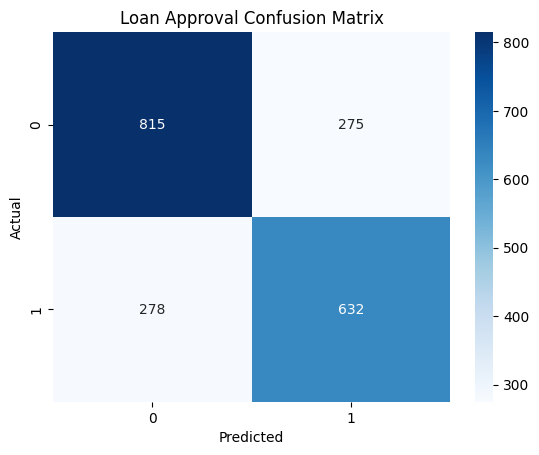

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Approval Confusion Matrix")

plt.show()

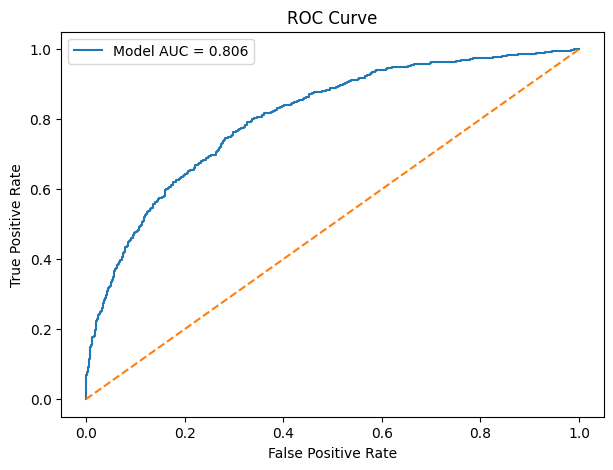

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Model AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

a/b testing


In [ ]:
ab_test = X_test.copy()

ab_test["ActualApproval"] = y_test.values

ab_test["ML_Probability"] = y_probability

ab_test = ab_test.reset_index(drop=True)

ab_test.head()

,Age,Income,CreditScore,LoanAmount,LoanTerm,EmploymentYears,ExistingLoans,DebtToIncome,EmploymentType,Education,ActualApproval,ML_Probability
0,37,140295,520,805861,36,16,2,0.64,Self-Employed,Undergraduate,0,0.242145
1,42,169360,370,709319,24,9,4,0.37,Business,Graduate,0,0.136527
2,29,53575,794,217041,48,5,2,0.47,Salaried,Graduate,1,0.709218
3,21,22369,506,586772,48,16,0,0.17,Salaried,Undergraduate,1,0.532160
4,41,117540,592,476427,60,14,3,0.46,Self-Employed,Graduate,1,0.484683


In [ ]:
np.random.seed(42)

ab_test["Group"] = np.random.choice(
    ["Control", "Treatment"],
    size=len(ab_test)
)

ab_test.head()

,Age,Income,CreditScore,LoanAmount,LoanTerm,EmploymentYears,ExistingLoans,DebtToIncome,EmploymentType,Education,ActualApproval,ML_Probability,Group
0,37,140295,520,805861,36,16,2,0.64,Self-Employed,Undergraduate,0,0.242145,Control
1,42,169360,370,709319,24,9,4,0.37,Business,Graduate,0,0.136527,Treatment
2,29,53575,794,217041,48,5,2,0.47,Salaried,Graduate,1,0.709218,Control
3,21,22369,506,586772,48,16,0,0.17,Salaried,Undergraduate,1,0.532160,Control
4,41,117540,592,476427,60,14,3,0.46,Self-Employed,Graduate,1,0.484683,Control


In [ ]:
np.random.seed(42)

ab_test["Group"] = np.random.choice(
    ["Control", "Treatment"],
    size=len(ab_test)
)

ab_test.head()

,Age,Income,CreditScore,LoanAmount,LoanTerm,EmploymentYears,ExistingLoans,DebtToIncome,EmploymentType,Education,ActualApproval,ML_Probability,Group
0,37,140295,520,805861,36,16,2,0.64,Self-Employed,Undergraduate,0,0.242145,Control
1,42,169360,370,709319,24,9,4,0.37,Business,Graduate,0,0.136527,Treatment
2,29,53575,794,217041,48,5,2,0.47,Salaried,Graduate,1,0.709218,Control
3,21,22369,506,586772,48,16,0,0.17,Salaried,Undergraduate,1,0.532160,Control
4,41,117540,592,476427,60,14,3,0.46,Self-Employed,Graduate,1,0.484683,Control


In [ ]:
ab_test["OldPolicyApproval"] = np.where(
    (ab_test["CreditScore"] >= 650) &
    (ab_test["DebtToIncome"] <= 0.45),
    1,
    0
)

In [ ]:
ab_test["MLPolicyApproval"] = np.where(
    ab_test["ML_Probability"] >= 0.50,
    1,
    0
)

In [ ]:
ab_test["PolicyApproval"] = np.where(
    ab_test["Group"] == "Control",
    ab_test["OldPolicyApproval"],
    ab_test["MLPolicyApproval"]
)

ab_test.head()

,Age,Income,CreditScore,LoanAmount,LoanTerm,EmploymentYears,ExistingLoans,DebtToIncome,EmploymentType,Education,ActualApproval,ML_Probability,Group,OldPolicyApproval,MLPolicyApproval,PolicyApproval
0,37,140295,520,805861,36,16,2,0.64,Self-Employed,Undergraduate,0,0.242145,Control,0,0,0
1,42,169360,370,709319,24,9,4,0.37,Business,Graduate,0,0.136527,Treatment,0,0,0
2,29,53575,794,217041,48,5,2,0.47,Salaried,Graduate,1,0.709218,Control,0,1,0
3,21,22369,506,586772,48,16,0,0.17,Salaried,Undergraduate,1,0.532160,Control,0,1,0
4,41,117540,592,476427,60,14,3,0.46,Self-Employed,Graduate,1,0.484683,Control,0,0,0


In [ ]:
control = ab_test[ab_test["Group"] == "Control"]

treatment = ab_test[ab_test["Group"] == "Treatment"]

control_total = len(control)
treatment_total = len(treatment)

control_success = control["PolicyApproval"].sum()
treatment_success = treatment["PolicyApproval"].sum()

control_rate = control_success / control_total
treatment_rate = treatment_success / treatment_total

print("Control customers:", control_total)
print("Treatment customers:", treatment_total)

print("\nControl approval rate:",
      round(control_rate * 100, 2), "%")

print("Treatment approval rate:",
      round(treatment_rate * 100, 2), "%")

Control customers: 1016
Treatment customers: 984

Control approval rate: 18.6 %
Treatment approval rate: 42.99 %


In [ ]:
absolute_lift = treatment_rate - control_rate

relative_lift = (
    (treatment_rate - control_rate)
    / control_rate
) * 100

print("Absolute lift:",
      round(absolute_lift * 100, 2), "percentage points")

print("Relative lift:",
      round(relative_lift, 2), "%")

Absolute lift: 24.39 percentage points
Relative lift: 131.09 %


In [ ]:
pooled_p = (
    (control_success + treatment_success)
    /
    (control_total + treatment_total)
)

print("Pooled proportion:", pooled_p)

Pooled proportion: 0.306


In [ ]:
standard_error = np.sqrt(
    pooled_p * (1 - pooled_p) *
    (
        1 / control_total +
        1 / treatment_total
    )
)

print("Standard error:", standard_error)

Standard error: 0.020611568552880728


In [ ]:
z_score = (
    treatment_rate - control_rate
) / standard_error

print("Z-score:", z_score)

Z-score: 11.830949503314825


In [ ]:
p_value = 2 * (
    1 - norm.cdf(abs(z_score))
)

print("P-value:", p_value)

P-value: 0.0


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant")
    print("Reject the null hypothesis.")
    print("The new ML policy has a significant difference in approval rate.")
else:
    print("Result: Not statistically significant")
    print("Fail to reject the null hypothesis.")
    print("There is not enough evidence that the ML policy changed approval rate.")

Result: Statistically significant
Reject the null hypothesis.
The new ML policy has a significant difference in approval rate.


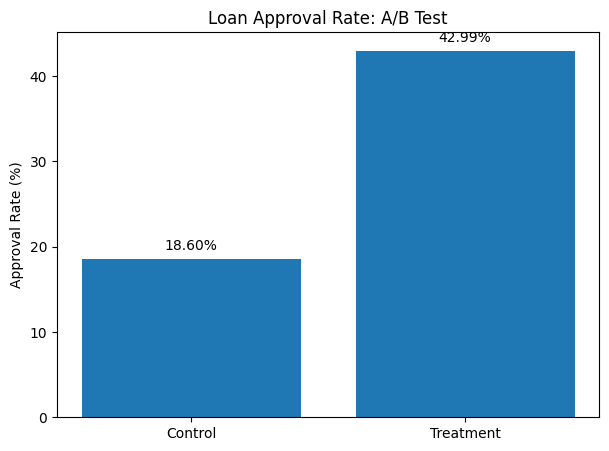

In [ ]:
rates = [
    control_rate * 100,
    treatment_rate * 100
]

groups = [
    "Control",
    "Treatment"
]

plt.figure(figsize=(7, 5))

plt.bar(groups, rates)

plt.ylabel("Approval Rate (%)")
plt.title("Loan Approval Rate: A/B Test")

for i, value in enumerate(rates):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

In [ ]:
results = pd.DataFrame({
    "Group": ["Control", "Treatment"],
    "Customers": [control_total, treatment_total],
    "Approved": [control_success, treatment_success],
    "Approval Rate": [
        control_rate,
        treatment_rate
    ]
})

results

,Group,Customers,Approved,Approval Rate
0,Control,1016,189,0.186024
1,Treatment,984,423,0.429878


In [ ]:
results["Approval Rate"] = (
    results["Approval Rate"] * 100
).round(2)

results

,Group,Customers,Approved,Approval Rate
0,Control,1016,189,18.60
1,Treatment,984,423,42.99


In [ ]:
print("========== A/B TEST SUMMARY ==========")

print(f"Control approval rate: {control_rate*100:.2f}%")
print(f"Treatment approval rate: {treatment_rate*100:.2f}%")

print(f"Absolute lift: {absolute_lift*100:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2f}%")

print(f"Z-score: {z_score:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("\nDecision: Adopt the ML policy, subject to risk and profitability checks.")
else:
    print("\nDecision: Do not conclude that the ML policy improves approval rate.")

========== A/B TEST SUMMARY ==========
Control approval rate: 18.60%
Treatment approval rate: 42.99%
Absolute lift: 24.39 percentage points
Relative lift: 131.09%
Z-score: 11.8309
P-value: 0.000000

Decision: Adopt the ML policy, subject to risk and profitability checks.
